<a href="https://colab.research.google.com/github/Ama-an-nu/Stars-Galaxies-and-Quasars_Prediction/blob/main/Predicting_Stars%2C_Galaxies_and_Quasars.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Importing Neccessary Libararies
import os

'''Data Handling & Linear Algebra'''
import numpy as np
import pandas as pd

'''Visualisation'''
import matplotlib.pyplot as plt
import seaborn as sns

'''Manipulating Data and Model Building'''
import tensorflow as tf
from tensorflow import keras

'''Data Analysis'''
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

'''Measuring Classification Performance'''
from sklearn.metrics import accuracy_score

'''Classification & Regression'''
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC


'''Ignore warnings'''
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [2]:
df = pd.read_csv("star_classification.csv")

In [3]:
df.head()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


In [4]:
df.shape

(100000, 18)

In [6]:
df.drop(["obj_ID", "spec_obj_ID"], axis = 1, inplace= True)

In [7]:
df.head()

,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,class,redshift,plate,MJD,fiber_ID
0,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,GALAXY,0.634794,5812,56354,171
1,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,GALAXY,0.779136,10445,58158,427
2,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,GALAXY,0.644195,4576,55592,299
3,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,GALAXY,0.932346,9149,58039,775
4,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,GALAXY,0.116123,6121,56187,842


In [8]:
df.shape

(100000, 16)

In [16]:
df.describe()

,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,redshift,plate,MJD,fiber_ID
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.0,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,177.629117,24.135305,21.980468,20.531387,19.645762,19.084854,18.668810,4481.366060,301.0,3.511610,186.130520,0.576661,5137.009660,55588.647500,449.312740
std,96.502241,19.644665,31.769291,31.750292,1.854760,1.757895,31.728152,1964.764593,0.0,1.586912,149.011073,0.730707,2952.303351,1808.484233,272.498404
min,0.005528,-18.785328,-9999.000000,-9999.000000,9.822070,9.469903,-9999.000000,109.000000,301.0,1.000000,11.000000,-0.009971,266.000000,51608.000000,1.000000
25%,127.518222,5.146771,20.352353,18.965230,18.135828,17.732285,17.460677,3187.000000,301.0,2.000000,82.000000,0.054517,2526.000000,54234.000000,221.000000
50%,180.900700,23.645922,22.179135,21.099835,20.125290,19.405145,19.004595,4188.000000,301.0,4.000000,146.000000,0.424173,4987.000000,55868.500000,433.000000
75%,233.895005,39.901550,23.687440,22.123767,21.044785,20.396495,19.921120,5326.000000,301.0,5.000000,241.000000,0.704154,7400.250000,56777.000000,645.000000
max,359.999810,83.000519,32.781390,31.602240,29.571860,32.141470,29.383740,8162.000000,301.0,6.000000,989.000000,7.011245,12547.000000,58932.000000,1000.000000


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   alpha     100000 non-null  float64
 1   delta     100000 non-null  float64
 2   u         100000 non-null  float64
 3   g         100000 non-null  float64
 4   r         100000 non-null  float64
 5   i         100000 non-null  float64
 6   z         100000 non-null  float64
 7   run_ID    100000 non-null  int64  
 8   rerun_ID  100000 non-null  int64  
 9   cam_col   100000 non-null  int64  
 10  field_ID  100000 non-null  int64  
 11  class     100000 non-null  object 
 12  redshift  100000 non-null  float64
 13  plate     100000 non-null  int64  
 14  MJD       100000 non-null  int64  
 15  fiber_ID  100000 non-null  int64  
dtypes: float64(8), int64(7), object(1)
memory usage: 12.2+ MB


In [13]:
df.isnull().sum()

,0
alpha,0
delta,0
u,0
g,0
r,0
i,0
z,0
run_ID,0
rerun_ID,0
cam_col,0


In [17]:
# Encoding 'Class' Feature
le = LabelEncoder().fit(df['class'])
df['class'] = le.transform(df['class'])

In [20]:
df.head(10)

,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,class,redshift,plate,MJD,fiber_ID
0,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,0,0.634794,5812,56354,171
1,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,0,0.779136,10445,58158,427
2,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,0,0.644195,4576,55592,299
3,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,0,0.932346,9149,58039,775
4,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,0,0.116123,6121,56187,842
5,340.995121,20.589476,23.48827,23.33776,21.32195,20.25615,19.54544,8102,301,3,110,1,1.424659,5026,55855,741
6,23.234926,11.418188,21.46973,21.17624,20.92829,20.60826,20.42573,7773,301,2,462,1,0.586455,11069,58456,113
7,5.433176,12.065186,22.24979,22.02172,20.34126,19.48794,18.84999,7773,301,2,346,0,0.477009,6183,56210,15
8,200.290475,47.199402,24.40286,22.35669,20.61032,19.46490,18.95852,3716,301,5,108,0,0.660012,6625,56386,719
9,39.149691,28.102842,21.74669,20.03493,19.17553,18.81823,18.65422,5934,301,4,122,2,-0.000008,2444,54082,232


In [21]:
df['class'].unique()
# G = 0, Q= 1, S = 2

array([0, 1, 2])

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   alpha     100000 non-null  float64
 1   delta     100000 non-null  float64
 2   u         100000 non-null  float64
 3   g         100000 non-null  float64
 4   r         100000 non-null  float64
 5   i         100000 non-null  float64
 6   z         100000 non-null  float64
 7   run_ID    100000 non-null  int64  
 8   rerun_ID  100000 non-null  int64  
 9   cam_col   100000 non-null  int64  
 10  field_ID  100000 non-null  int64  
 11  class     100000 non-null  int64  
 12  redshift  100000 non-null  float64
 13  plate     100000 non-null  int64  
 14  MJD       100000 non-null  int64  
 15  fiber_ID  100000 non-null  int64  
dtypes: float64(8), int64(8)
memory usage: 12.2 MB


# Splitting Data

In [23]:
X = df.drop('class', axis = 1)
y = df['class']

# Scaling

In [24]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler(copy = True, with_mean=True, with_std=True)
X = scaler.fit_transform(X)

In [27]:
X[:10]

array([[-4.34603584e-01,  4.25528706e-01,  5.97545987e-02,
         5.49261638e-02,  4.03961550e-01,  4.60074020e-02,
         3.93657668e-03, -4.45534513e-01,  0.00000000e+00,
        -9.52552725e-01, -7.18946946e-01,  7.95572845e-02,
         2.28632913e-01,  4.23203207e-01, -1.02134224e+00],
       [-3.39921434e-01,  3.63402270e-01,  8.80452678e-02,
         7.24561688e-02,  1.58440609e+00,  1.18509719e+00,
         9.28347300e-02,  1.86455534e-02,  0.00000000e+00,
         9.37920462e-01, -4.50509177e-01,  2.77096198e-01,
         1.79792394e+00,  1.42072864e+00, -8.18825036e-02],
       [-3.67250583e-01,  5.82712741e-01,  1.03326768e-01,
         6.71651675e-02,  5.19745322e-01,  1.50018697e-01,
         8.80798469e-03, -4.45534513e-01,  0.00000000e+00,
        -9.52552725e-01, -4.43798232e-01,  9.24228290e-02,
        -1.90025346e-01,  1.85377163e-03, -5.51612374e-01],
       [ 1.66952317e+00, -1.24910526e+00,  4.92149837e-03,
         1.02209744e-01,  1.05990425e+00,  8.07609690

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=128)

<Axes: xlabel='class', ylabel='count'>

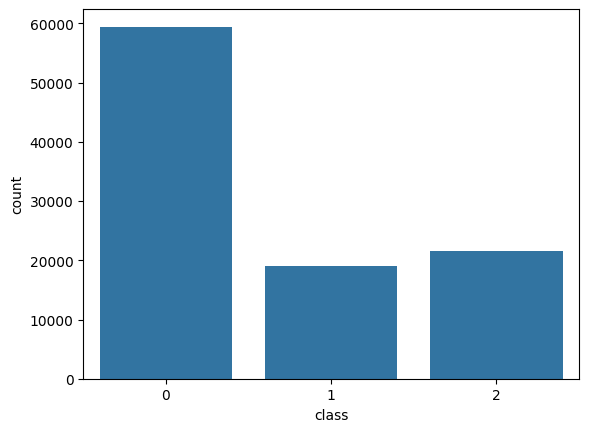

In [29]:
sns.countplot(x = df['class'])

# We have around 60k Galaxies labeled as 0
# We have around 20k Quasars labeled as 1
# We have above 20k Stars labeled as 2

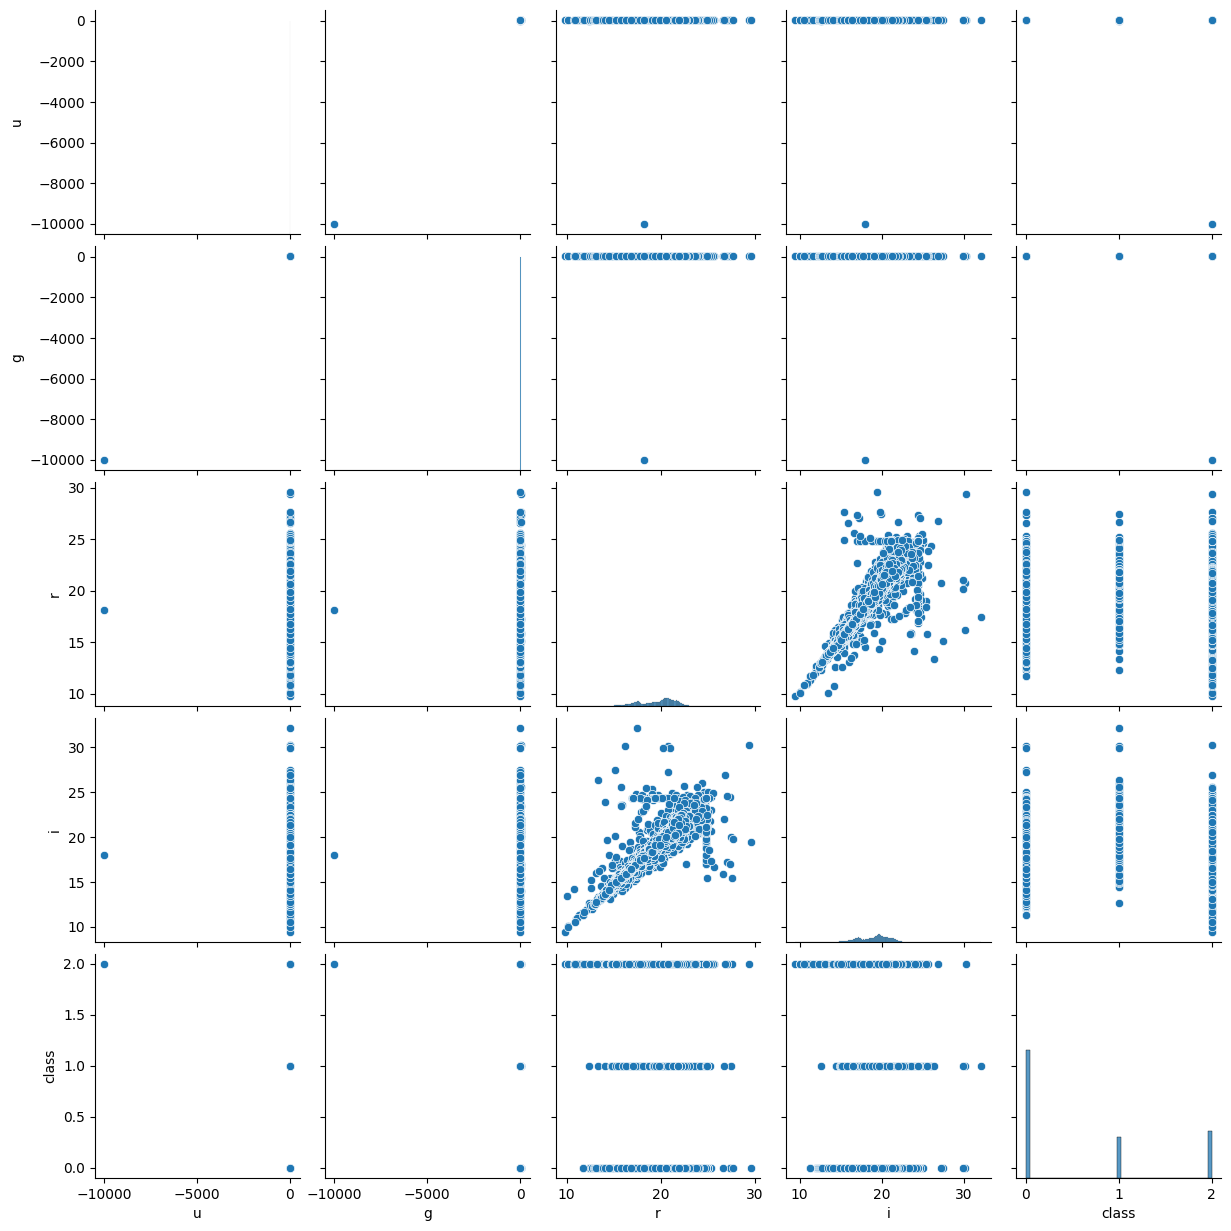

In [31]:
sns.pairplot(df[['u', 'g', 'r', 'i', 'class']])

# Modelling
- Three Model we are using then calculate which performs better
- Decision Tree, Logistic Tree, K-Neighbor

In [34]:
dtClassifier = DecisionTreeClassifier(max_leaf_nodes=15, max_depth=3)


In [35]:
LRclassifier = LogisticRegression()

In [36]:
NeNeClassifier = KNeighborsClassifier(n_neighbors=3)

In [37]:
dtClassifier.fit(X_train, y_train)
LRclassifier.fit(X_train, y_train)
NeNeClassifier.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [38]:
y_preds = dtClassifier.predict(X_test)
y_predsLR = LRclassifier.predict(X_test)
y_predsNeNe = NeNeClassifier.predict(X_test)


In [39]:
#Displaying the last 10 predictions on the test split as output by all the models

print(y_preds[:10],'\n',y_test[:10])

print("\n*******************************************************")
print(y_predsLR[:10],'\n',y_test[:10])

print("\n*******************************************************")
print(y_predsNeNe[:10],'\n',y_test[:10])

[1 0 0 1 2 0 1 2 0 0] 
 50360    1
97957    0
66018    1
37401    1
77344    2
77861    0
61685    1
39794    2
62088    0
54415    0
Name: class, dtype: int64

*******************************************************
[1 0 1 1 2 0 1 2 0 0] 
 50360    1
97957    0
66018    1
37401    1
77344    2
77861    0
61685    1
39794    2
62088    0
54415    0
Name: class, dtype: int64

*******************************************************
[1 0 1 1 2 0 1 2 0 0] 
 50360    1
97957    0
66018    1
37401    1
77344    2
77861    0
61685    1
39794    2
62088    0
54415    0
Name: class, dtype: int64


# Classification Metrics Report

In [67]:

from sklearn.metrics import classification_report, accuracy_score

target_names = ['0', '1', '2']

# Decision Tree
print('\033[1m Decision Tree - \033[0m')
print(classification_report(y_test, y_preds, target_names=target_names))
print("Accuracy:", accuracy_score(y_test, y_preds) * 100, "%\n")

# Logistic Regression
print('\033[1m Logistic Regression - \033[0m')
print(classification_report(y_test, y_predsLR, target_names=target_names))
print("Accuracy:", accuracy_score(y_test, y_predsLR) * 100, "%\n")

# KNN Classifier
print('\033[1m KNN Classifier - \033[0m')
print(classification_report(y_test, y_predsNeNe, target_names=target_names))
print("Accuracy:", accuracy_score(y_test, y_predsNeNe) * 100, "%")


 Decision Tree - 
              precision    recall  f1-score   support

           0       0.94      0.98      0.96     17878
           1       0.94      0.80      0.86      5629
           2       0.99      1.00      1.00      6493

    accuracy                           0.95     30000
   macro avg       0.96      0.93      0.94     30000
weighted avg       0.95      0.95      0.95     30000

Accuracy: 95.16666666666667 %

 Logistic Regression - 
              precision    recall  f1-score   support

           0       0.96      0.97      0.96     17878
           1       0.95      0.88      0.91      5629
           2       0.95      1.00      0.97      6493

    accuracy                           0.96     30000
   macro avg       0.95      0.95      0.95     30000
weighted avg       0.96      0.96      0.96     30000

Accuracy: 95.71333333333332 %

 KNN Classifier - 
              precision    recall  f1-score   support

           0       0.89      0.96      0.92     17878
      

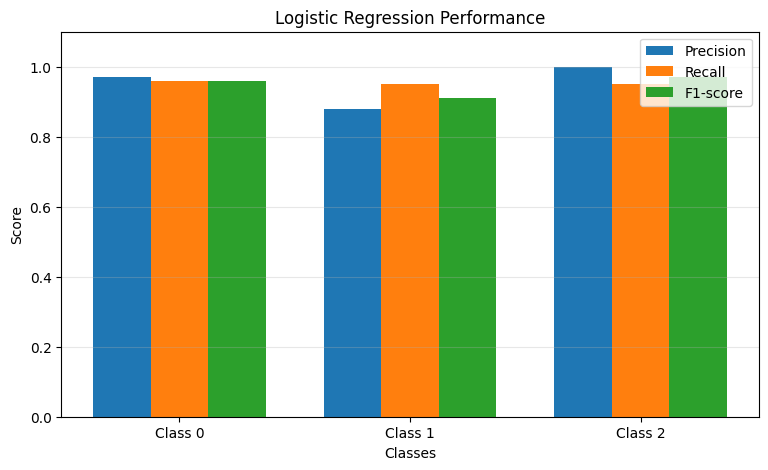

In [69]:
# Vizualisation of Logistic regression model classification report
classes = ['Class 0', 'Class 1', 'Class 2']

precision = [0.97, 0.88, 1.00]
recall = [0.96, 0.95, 0.95]
f1_score = [0.96, 0.91, 0.97]

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(9, 5))

plt.bar(x - width, precision, width, label='Precision')
plt.bar(x, recall, width, label='Recall')
plt.bar(x + width, f1_score, width, label='F1-score')

plt.xlabel('Classes')
plt.ylabel('Score')
plt.title('Logistic Regression Performance')
plt.xticks(x, classes)
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()


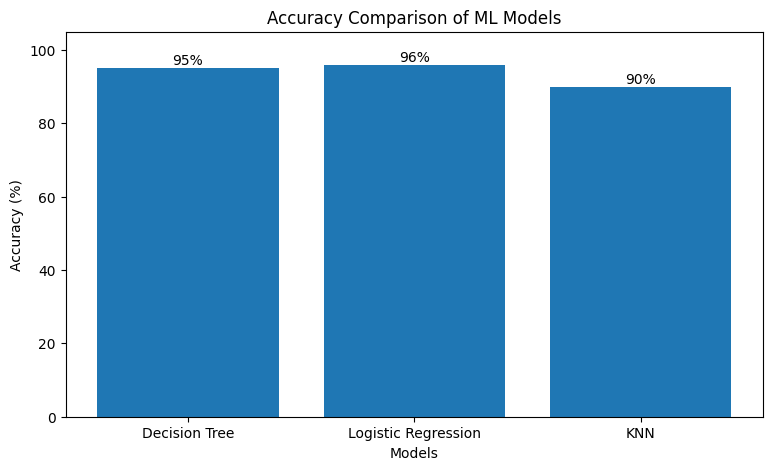

In [72]:
# Comparing All 3 models based on accuracy
models = ['Decision Tree', 'Logistic Regression', 'KNN']

accuracy = [95, 96, 90]


# Accuracy comparison
plt.figure(figsize=(9, 5))
plt.bar(models, accuracy)

plt.title('Accuracy Comparison of ML Models')
plt.xlabel('Models')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 105)

for i, v in enumerate(accuracy):
    plt.text(i, v + 1, str(v) + '%', ha='center')

plt.show()

